# Plan

The idea is to understand and implement mini versions of these architectures.

The dataset we're going to use is MNIST digits. We need to scale down the images.

1. Simple CNN: (Basic Mechanics)

- https://medium.com/@myringoleMLGOD/simple-convolutional-neural-network-cnn-for-dummies-in-pytorch-a-step-by-step-guide-6f4109f6df80
- https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/
- https://github.com/Bengal1/Simple-CNN-Guide
- https://medium.com/@chenycy/a-simple-convolutional-neural-network-cnn-classifier-based-on-real-images-084110d52c18


2. AlexNet: (The History of Scaling)

- https://proceedings.neurips.cc/paper_files/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf


3. MobileNets: (Engineering for Constraints)

4. Vision Transformer (ViT): (The Modern Paradigm)

5. Vision Mamba (VMamba): (The 2026 Efficiency Frontier)



# Convolution Neural Networks - CNN

## CNN parameters

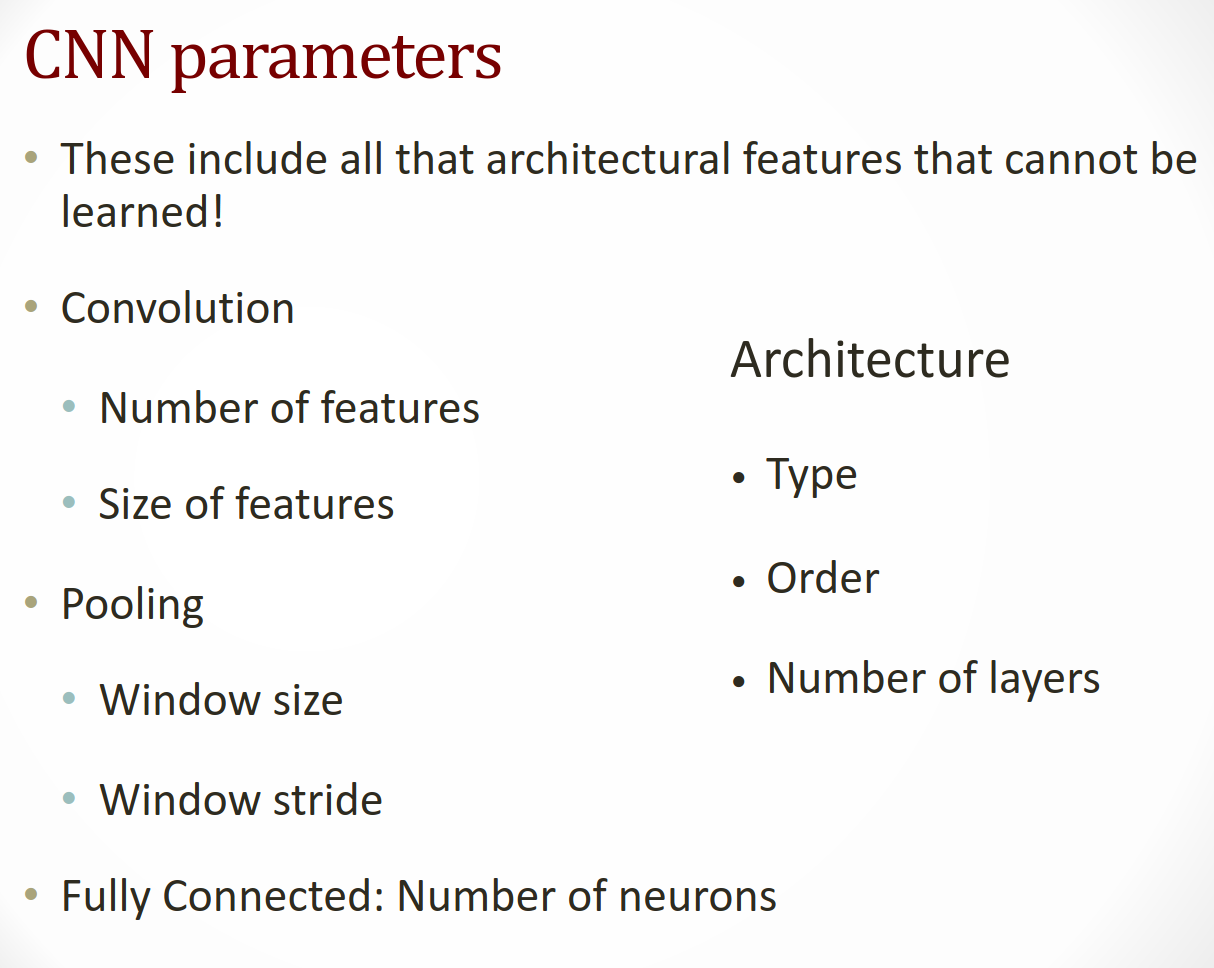
Image pulled from multimedia AI lecture slides.

## Convolutions

Kernels act as filters for specific features.


Extracting edges from an image helps identity the type of image.
- Edge extraction from an image is feature extraction.
- A CNN can be used to extract those type of features - edges
- Convolutions = multiplication + addition

A convolution applies **a kernel across** an image.

This kernel extract image features: edges, lines, etc..


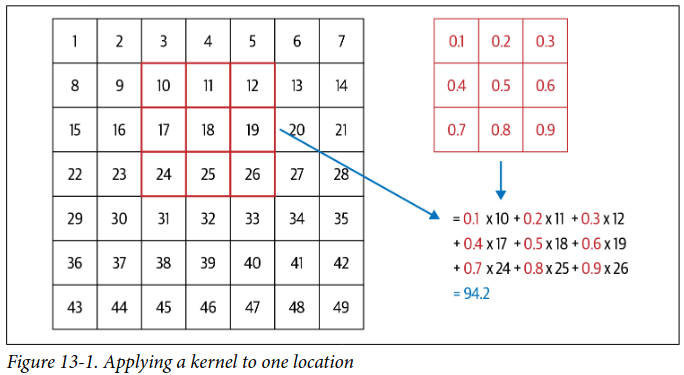

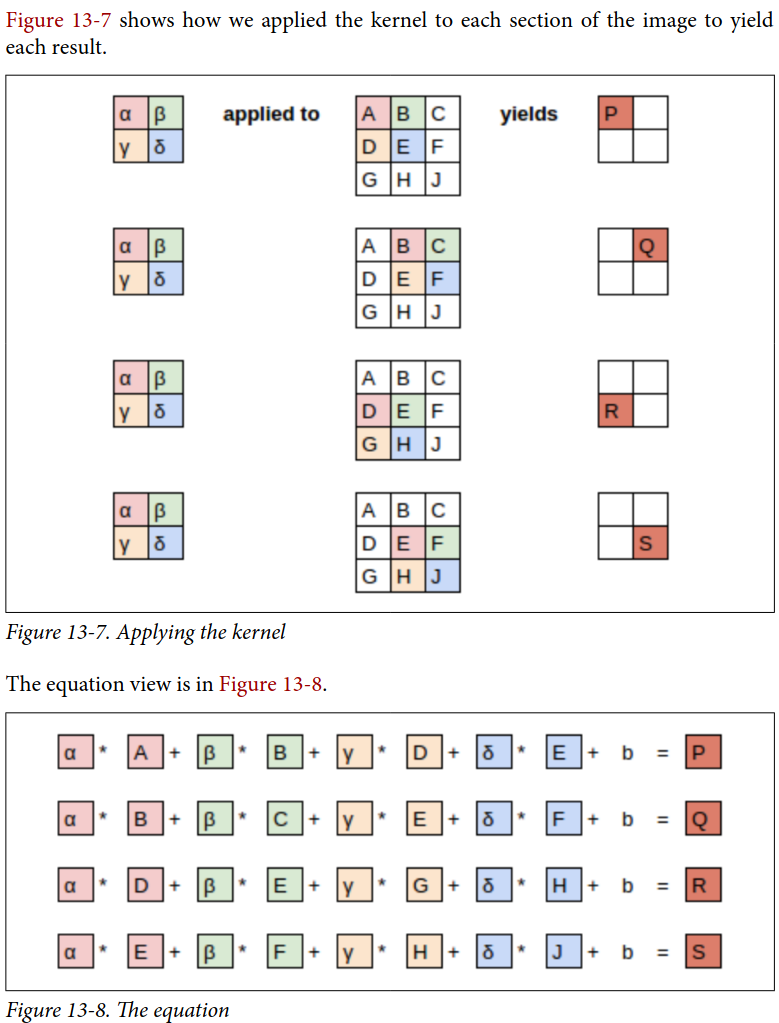

Figures from Fastbook

The output of a convolution: feature map or activation map.


## Stride

Steps size with which the filter moves across the input image.

A larger stride size, downsamples the feature map.

- Stride-2 convolutions downsample the input feature map to half.
- Stride-1 convoltions preserve the input feature map size.


## Padding

Adds extra pixels around the input image.

THese pixels are set to zero

Padding is used to fit the filter over the image.

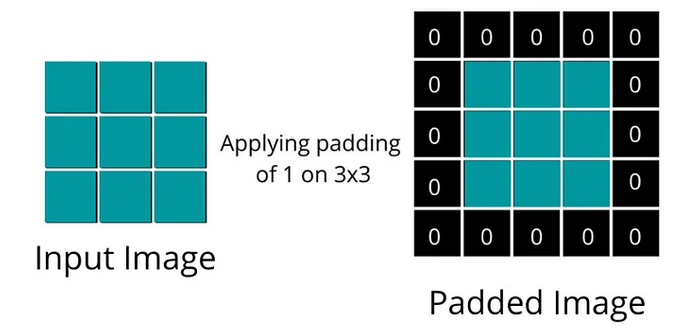
Image from: https://medium.com/@myringoleMLGOD/simple-convolutional-neural-network-cnn-for-dummies-in-pytorch-a-step-by-step-guide-6f4109f6df80


## Feature maps

Is the output from the convolultion layer - applied filters on the image.

Each feature map captures different features of the input image.

Stacking feature maps together forms the input for the next layer.

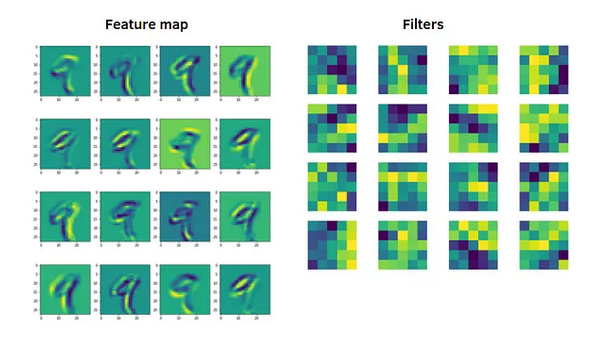
Image: https://medium.com/@myringoleMLGOD/simple-convolutional-neural-network-cnn-for-dummies-in-pytorch-a-step-by-step-guide-6f4109f6df80


## Pooling Layers

Pooling layers reduce the size of the feature maps.
- REduce overfitting
- REduce the model size
- You set the pooling window size.
- You set the stride.

Two types of pooling.


### Max pooling

- More common in practice.
- Takes the max values of a feature map.
- Reduces the feature maps size to half
- Placed between convolution layers


### Average pooling

- Takes the average of the patches of the feature map.

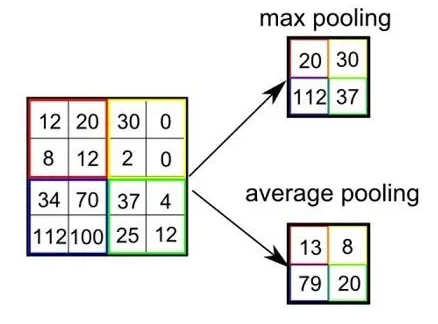
Image src: https://medium.com/@myringoleMLGOD/simple-convolutional-neural-network-cnn-for-dummies-in-pytorch-a-step-by-step-guide-6f4109f6df80




# Setup Dataset

In [1]:
import mikroml.datasets
import torch

/home/master/.pyenv/versions/miniconda3-latest/envs/ml/lib/python3.10/site-packages/torch/cuda/__init__.py:54: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
mnist_ds = mikroml.datasets.MNIST_Dataset()

In [3]:
X_train_tens, y_train_tens, X_valid_tens, y_valid_tens = map(torch.tensor, (mnist_ds.train_x, mnist_ds.train_y,  mnist_ds.valid_x, mnist_ds.valid_y))

In [5]:
X_train_tens.shape, y_train_tens.shape

(torch.Size([50000, 784]), torch.Size([50000]))

Create the kernel.

# Simple CNN

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [11]:
label = mnist_ds.train_y[0]
number = mnist_ds.train_x[0]
number.shape, label

((784,), 5)

In [12]:
number_5 = np.reshape(number, (28, 28))
num5_t = torch.tensor(number_5)

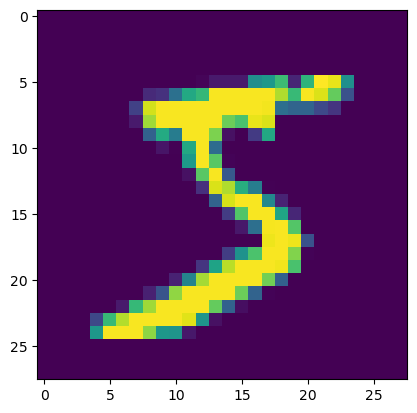

In [13]:
plt.imshow(number_5)

In [14]:
 number_5.shape

(28, 28)

In [15]:
top_edge_kernel = torch.tensor(
    [
        [-1, -1, -1],
        [0, 0, 0],
        [1, 1, 1],
    ]
).float()

In [16]:
num5_t[0:3,0:3]

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [17]:
(num5_t[0:3,0:3] * top_edge_kernel).sum()

tensor(0.)

In [18]:
df = pd.DataFrame(num5_t[:20,0:26])
df.style.set_properties(**{'font-size':'6pt'}).background_gradient('Greys')

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.011719,0.070312,0.070312,0.070312,0.492188,0.531250,0.683594,0.101562,0.648438,0.996094,0.964844,0.496094,0.000000,0.000000
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.117188,0.140625,0.367188,0.601562,0.664062,0.988281,0.988281,0.988281,0.988281,0.988281,0.878906,0.671875,0.988281,0.945312,0.761719,0.250000,0.000000,0.000000
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.191406,0.929688,0.988281,0.988281,0.988281,0.988281,0.988281,0.988281,0.988281,0.988281,0.980469,0.363281,0.320312,0.320312,0.218750,0.152344,0.000000,0.000000,0.000000
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.070312,0.855469,0.988281,0.988281,0.988281,0.988281,0.988281,0.773438,0.710938,0.964844,0.941406,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.312500,0.609375,0.417969,0.988281,0.988281,0.800781,0.042969,0.000000,0.167969,0.601562,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [19]:
(num5_t[5:5+3,10:10+3] * top_edge_kernel).sum()

tensor(2.9531)

In [20]:
def apply_kernel(img_t, row, col, kernel):
    # Apply kernel over image
    return (img_t[row-1:row+2, col-1:col+2] * kernel).sum()

In [21]:
[(i,j) for i in range(1, 5) for j in range(1, 5)]

[(1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4)]

In [22]:
# 2D tensor
top_edge5 = torch.tensor(
    [[apply_kernel(num5_t, i, j, top_edge_kernel) for j in range(1, 27)] for i in range(1, 27)]
)
top_edge5.shape

torch.Size([26, 26])

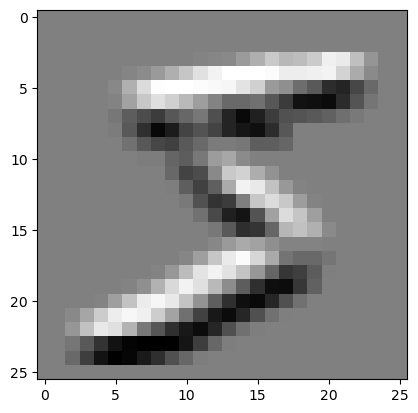

In [23]:
plt.imshow(top_edge5, cmap="gray")

Explaining the feature map size.

**For input image of Height h and Width w there are h-2 and w-2 windows we can fit. Results feature map `[h-2,w-2]`**.

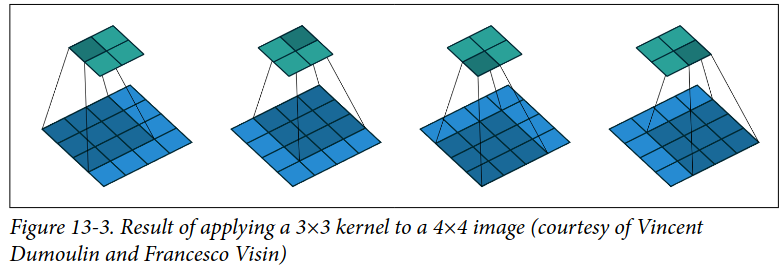

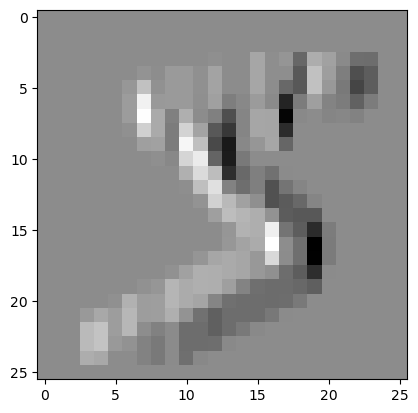

In [24]:
left_edge_kernel = torch.tensor([
    [-1, 1, 0],
    [-1, 1, 0],
    [-1, 1, 0]
]).float()

left_edge5 = torch.tensor(
    [[apply_kernel(num5_t, i, j, left_edge_kernel) for j in range(1, 27)] for i in range(1, 27)]
)
left_edge5.shape
plt.imshow(left_edge5, cmap="gray")

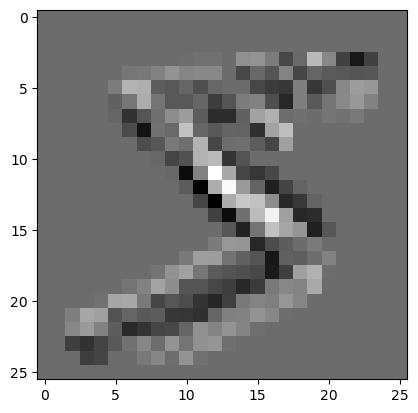

In [25]:
diag_main_kernel = torch.tensor([
    [1, -1, 0],
    [0, 1, -1],
    [-1, 0, 1]
]).float()

main_diag5 = torch.tensor(
    [[apply_kernel(num5_t, i, j, diag_main_kernel) for j in range(1, 27)] for i in range(1, 27)]
)
main_diag5.shape
plt.imshow(main_diag5, cmap="gray")

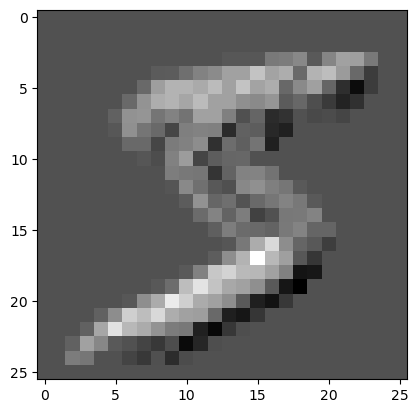

In [26]:
diag_sec_kernel = torch.tensor([
    [0, -1, 1],
    [-1, 1, 0],
    [1, 0, 0]
]).float()

sec_diag5 = torch.tensor(
    [[apply_kernel(num5_t, i, j, diag_sec_kernel) for j in range(1, 27)] for i in range(1, 27)]
)
sec_diag5.shape
plt.imshow(sec_diag5, cmap="gray")

`PyTorch` applies multiple kernels at the same time.

In [27]:
kernels = torch.stack([left_edge_kernel, top_edge_kernel, diag_main_kernel, diag_sec_kernel])
print(kernels.shape)
type(kernels)

torch.Size([4, 3, 3])


torch.Tensor

Pass by Conv2D

In [28]:
print(kernels.reshape((4, 1, 3, 3)).shape)
kernels4d = kernels.reshape((4, 1, 3, 3))

torch.Size([4, 1, 3, 3])


In [29]:
X_train_tens.shape

torch.Size([50000, 784])

In [30]:
X_train_tens = X_train_tens.reshape((50000, 28, 28))
X_train_tens.shape, y_train_tens.shape

(torch.Size([50000, 28, 28]), torch.Size([50000]))

In [31]:
# Create DL
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset


# Join 2 tensors into one
dataset = TensorDataset(X_train_tens, y_train_tens)
train_dataloader = DataLoader(dataset, batch_size=64)

In [32]:
imgs, lbls = next(iter(train_dataloader))

In [33]:
imgs.shape, lbls.shape

(torch.Size([64, 28, 28]), torch.Size([64]))

In [34]:
imgs = imgs.reshape((64, 1, 28, 28))
imgs.shape # Conv2d requires the addtional dimension

torch.Size([64, 1, 28, 28])

Use torch function to calculate convolution.
`torch.nn.functional.conv2d` also performs the **summation** over channels, but, **NOT over kernels**.

In my case, each kernel outputs a 26x26 feature map for each kernel and these features are in the 2nd dimension (4).

In [35]:
batch_features = torch.nn.functional.conv2d(imgs, kernels4d)
batch_features.shape

torch.Size([64, 4, 26, 26])

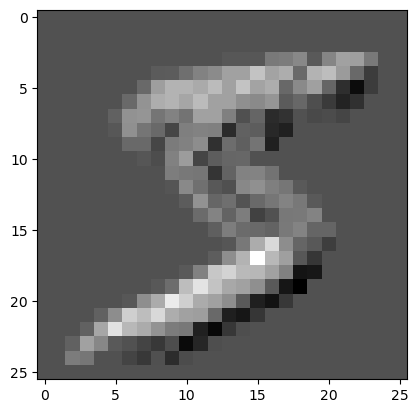

In [36]:
# This
# plt.imshow(sec_diag5, cmap="gray")
# is equal to
plt.imshow(batch_features[0, -1], cmap="gray")

How much padding we have to add?

For an odd-sized kernel `ks*ks` we need `ks//2` padding on all edges.

- The most **common kernel size in practice is 3×3**
- **The most common padding is 1**.
- 2-stride convolutions decrease the feature map size.

#### Calculators
Calculating the dimension of the feature map.

In [37]:
h, w = X_train_tens[0].shape

In [38]:
from math import floor

def calc_feature_map_dim(in_img_size, pad_size, ker_size, str_size):
    """
    Calculate the dimensions of the output feature map.
    
    PARAMETERS:
    in_img_size: one side of the input image
    pad_size: size of the padding
    ker_size: size of a symmetrical kernel
    str_size: stride size
    """
    n_out = floor(((in_img_size+2*pad_size - ker_size) / str_size) + 1)
    print(n_out)

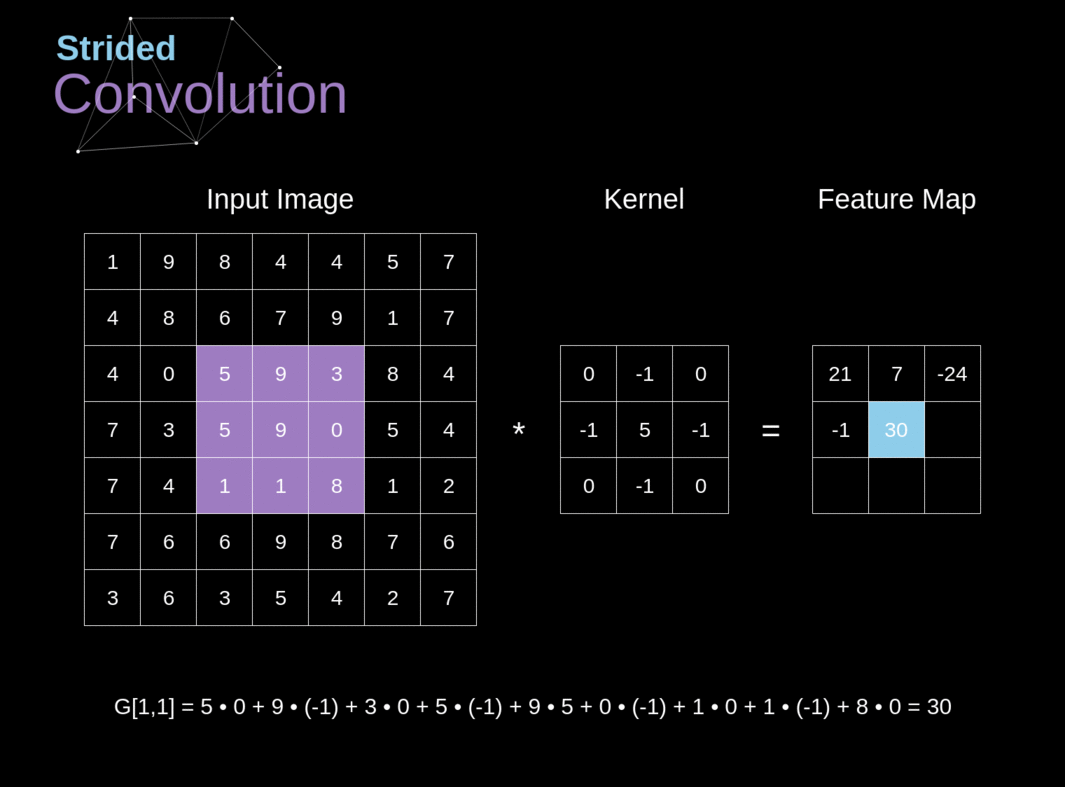
Image from: https://medium.com/data-science/gentle-dive-into-math-behind-convolutional-neural-networks-79a07dd44cf9

In [41]:
calc_feature_map_dim(
    7, 0, 3, 2
)

3


In [42]:
def calc_feature_map_dimension_t(img, padding, kernel, stride):
    h, w = img.shape
    ks = kernel.shape[0]
    fm_h = (h + 2*padding - kernel.shape[0]) // stride + 1
    fm_w = (w + 2*padding - kernel.shape[0]) // stride + 1
    return fm_h, fm_w

In [46]:
calc_feature_map_dimension_t(img=X_train_tens[0], padding=1, kernel=top_edge_kernel, stride=2)

(14, 14)

In [47]:
def calc_layer_output(inp, p, k, s):
    
    """
    Same as all previous ones.
    Less verbal.
    
    inp: input channels
    p: padding size
    k: kernel size
    s: stride sisze
    """
    o = (inp + 2*p - k) // s  + 1
    return o

In [48]:
calc_layer_output(7, 0, 3, 2)

3

We have to output a classifier, we can keep reducing the feature map size if we keep the strid=2 and ks=3.

In [49]:
# Classifier
binary_cnn = torch.nn.Sequential(
    # Input channel 1 - grayscale imges
    torch.nn.Conv2d(1, 4, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 4 feature maps, each 14x14 pixels
    torch.nn.Conv2d(4, 8, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 8 feature maps, each 7x7 pixels
    torch.nn.Conv2d(8, 16, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 16 feature maps, each 4x4 pixels
    torch.nn.Conv2d(16, 32, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # # 32 feature maps, each 2x2 pixels
    torch.nn.Conv2d(32, 2, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)),
    torch.nn.Flatten() # 2 feature maps 1x1 pixels
)

In [50]:
# Final output size = 2
binary_cnn(imgs).shape

torch.Size([64, 2])

**How to think about `in_channels` and `out_channels`?**


`in_channels` [1, 4, 8, 16, 32]:
- of the next layer must match `out_channels` of previous
- **this is the "what"**
- feature preduced by each layer
- it's **what** we want to learn
- they increase after each layer: [1, 4, 8, 16, 32]
- usually gets larger as you go deeper - because we want to learn more complex patterns

`out_channels`:
- **this is the "where"**
- they usually decrease after each layer - you're summarizing larger areas of the image


In [51]:
binary_cnn

Sequential(
  (0): Conv2d(1, 4, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(4, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): ReLU()
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (5): ReLU()
  (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (7): ReLU()
  (8): Conv2d(32, 2, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (9): Flatten(start_dim=1, end_dim=-1)
)

In [52]:
def count_parameters(model):
    tot_parms = 0
    for name, params in model.named_parameters():
        if params.requires_grad:
            print(f"name: {name}, params: {params.numel()}")
            tot_parms += params.numel()
    print(f"Total parameters: {tot_parms}")

In [53]:
count_parameters(binary_cnn)

name: 0.weight, params: 36
name: 0.bias, params: 4
name: 2.weight, params: 288
name: 2.bias, params: 8
name: 4.weight, params: 1152
name: 4.bias, params: 16
name: 6.weight, params: 4608
name: 6.bias, params: 32
name: 8.weight, params: 576
name: 8.bias, params: 2
Total parameters: 6722


The above can classify if a digit is a 0 or 1, but cannot classify all 10 digits.

This is an actual CNN in its simplest form.

MaxPooling is a later feature.

Normalization is a later feature.


###  TODO
- [x] split dataset into 2 categories
- [x] train network as a binary classifier - 2 digits
- [x] train the network as 10-digit classifier

### 2-digit (binary) classification

The networks outputs 2, raw logits. These are the 2 classes. To classify 2 digits, we need a loss function, softmax

Let's build the dataset to train the network on 3's and 5's.

In [54]:
train_mask = (y_train_tens == 3) | (y_train_tens == 5)

X_train_filtered = X_train_tens[train_mask]
y_train_filtered = y_train_tens[train_mask]

In [55]:
valid_mask = (y_valid_tens == 3) | (y_valid_tens == 5)

X_valid_filtered = X_valid_tens[valid_mask]
y_valid_filtered = y_valid_tens[valid_mask]

In [56]:
# -1 maintains dimensions
X_train_filtered = X_train_filtered.reshape(-1, 1, 28, 28).float()
X_train_filtered.shape

torch.Size([9607, 1, 28, 28])

In [57]:
X_valid_filtered = X_valid_filtered.reshape(-1, 1, 28, 28)
X_valid_filtered.shape

torch.Size([1945, 1, 28, 28])

In [58]:
# Convert to 0's and 1's for the categories
# Class 0 == 3, Class 1 == 5
y_train_filtered = (y_train_filtered == 5).long()
y_train_filtered.shape

torch.Size([9607])

In [59]:
def decipher_class(arr_t):
    # Class 1 == 5, Class 0 == 3
    if arr_t[0] > arr_t[1]:
        print("Predicted: Three")
    else:
        print("Predicted: Five")

In [60]:
y_valid_filtered = (y_valid_filtered == 5).long()
y_valid_filtered.shape, y_valid_filtered.unique()

(torch.Size([1945]), tensor([0, 1]))

In [61]:
# Create train dataloader
train_ds_bin = TensorDataset(X_train_filtered, y_train_filtered)
train_dl_bin = DataLoader(train_ds_bin, batch_size=64, shuffle=True)

In [62]:
# Create validation dataloader
valid_ds_bin = TensorDataset(X_valid_filtered, y_valid_filtered)
valid_dl_bin = DataLoader(valid_ds_bin, batch_size=64, shuffle=True)

In [63]:
from tqdm import tqdm

In [64]:
def train_function(model, loss_fn, optimizer, dataloader):
    model.train()
    size = len(dataloader.dataset)
    for batch_idx, (X, y) in enumerate(dataloader): # enumerate(tqdm(dataloader)):
        
        # Prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backprop
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch_idx % 10 == 0:
            print(f"loss: {loss:.3f}  Batch: [{batch_idx * X.shape[0]} / {size}]")

In [65]:
def build_binary_cnn():
    return torch.nn.Sequential(
    # Input channel 1 - grayscale imges
    torch.nn.Conv2d(1, 4, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 4 feature maps, each 14x14 pixels
    torch.nn.Conv2d(4, 8, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 8 feature maps, each 7x7 pixels
    torch.nn.Conv2d(8, 16, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 16 feature maps, each 4x4 pixels
    torch.nn.Conv2d(16, 32, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # # 32 feature maps, each 2x2 pixels
    torch.nn.Conv2d(32, 2, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)),
    torch.nn.Flatten() # 2 feature maps 1x1 pixels
)

In [66]:
# Let's train the network
binary_cnn = build_binary_cnn()

loss_fn = torch.nn.CrossEntropyLoss()

# optimizer = torch.optim.SGD(
#     binary_cnn.parameters(),
#     lr=1e-1
# )
optimizer = torch.optim.Adam(
    binary_cnn.parameters(),
    lr=1e-3
)

In [67]:
epochs = 4
for e in range(epochs):
    print(f"\nEpoch {e}\n------------")
    train_function(binary_cnn, loss_fn, optimizer, train_dl_bin)


Epoch 0
------------
loss: 0.697  Batch: [0 / 9607]
loss: 0.691  Batch: [640 / 9607]
loss: 0.699  Batch: [1280 / 9607]
loss: 0.669  Batch: [1920 / 9607]
loss: 0.624  Batch: [2560 / 9607]
loss: 0.482  Batch: [3200 / 9607]
loss: 0.367  Batch: [3840 / 9607]
loss: 0.235  Batch: [4480 / 9607]
loss: 0.226  Batch: [5120 / 9607]
loss: 0.100  Batch: [5760 / 9607]
loss: 0.161  Batch: [6400 / 9607]
loss: 0.152  Batch: [7040 / 9607]
loss: 0.143  Batch: [7680 / 9607]
loss: 0.181  Batch: [8320 / 9607]
loss: 0.170  Batch: [8960 / 9607]
loss: 0.054  Batch: [1050 / 9607]

Epoch 1
------------
loss: 0.101  Batch: [0 / 9607]
loss: 0.146  Batch: [640 / 9607]
loss: 0.159  Batch: [1280 / 9607]
loss: 0.137  Batch: [1920 / 9607]
loss: 0.076  Batch: [2560 / 9607]
loss: 0.046  Batch: [3200 / 9607]
loss: 0.098  Batch: [3840 / 9607]
loss: 0.056  Batch: [4480 / 9607]
loss: 0.036  Batch: [5120 / 9607]
loss: 0.091  Batch: [5760 / 9607]
loss: 0.112  Batch: [6400 / 9607]
loss: 0.083  Batch: [7040 / 9607]
loss: 0.030 

We need to test the performance of the trained neural net.

We also need the test dataloader.

In [68]:
def test_model(model, loss_fn, dataloader):
    test_loss, correct = 0, 0
    ds_size = len(dataloader.dataset)
    nof_batchs = len(dataloader)
    
    model.eval()
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            
            # Get the number
            test_loss += loss_fn(pred, y).item()
            
            # How many it got correct
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
            
    avg_loss = test_loss / nof_batchs        
    accuracy = correct / ds_size
    print(f"Accuracy {accuracy*100:.2f}%\n Avg. Loss: {avg_loss:.3f}")

In [69]:
test_model(binary_cnn, loss_fn, valid_dl_bin)

Accuracy 98.66%
 Avg. Loss: 0.043


#### Validate trained model

Let's validate the model on a single image, or a custom one from the test set.



In [70]:
X, y = next(iter(train_dl_bin))

In [71]:
X[1].shape, y[1]

(torch.Size([1, 28, 28]), tensor(1))

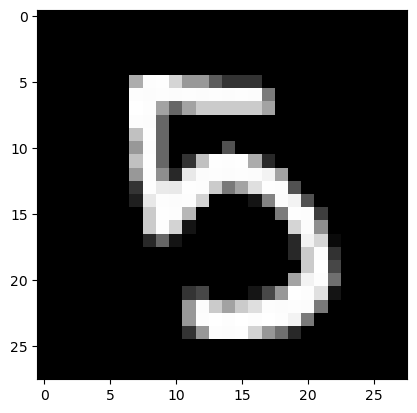

In [72]:
# We are going to test on this image
plt.imshow(X[1][0], cmap="gray")

In [73]:
img = X[1]
img.shape

torch.Size([1, 28, 28])

In [74]:
binary_cnn(img)

tensor([[-1.3467],
        [ 1.1181]], grad_fn=<ViewBackward0>)

In [75]:
# Prediction for one image with softmax
# Notes on dimension: https://stackoverflow.com/questions/61350445/what-is-the-purpose-of-the-dim-parameter-in-torch-nn-softmax
torch.nn.functional.softmax(binary_cnn(img), dim=0)

tensor([[0.0784],
        [0.9216]], grad_fn=<SoftmaxBackward0>)

In [76]:
# Sanity check - sum == 1
sum(torch.nn.functional.softmax(binary_cnn(img), dim=0))

tensor([1.], grad_fn=<AddBackward0>)

In [77]:
decipher_class(torch.nn.functional.softmax(binary_cnn(img), dim=0))

Predicted: Five


Let's use a random image online and valide on it.

In [78]:
import cv2
t = cv2.imread("./data/hand5.png", cv2.IMREAD_GRAYSCALE)
t = cv2.resize(t, (28,28))

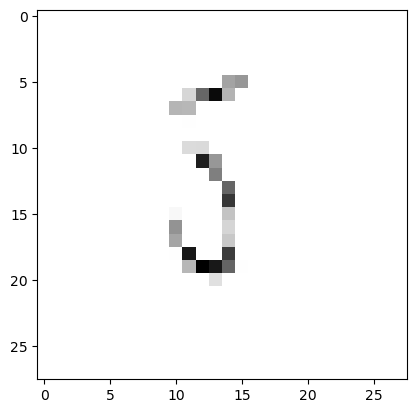

In [79]:
plt.imshow(t, cmap="gray")

In [80]:
# Prep for model input
t.resize(1,28,28)

In [81]:
torch.nn.functional.softmax(
    binary_cnn(torch.tensor(t).float()),
    dim=0
)

tensor([[1.],
        [0.]], grad_fn=<SoftmaxBackward0>)

In [82]:
arr_t = torch.nn.functional.softmax(
    binary_cnn(torch.tensor(t).float()),
    dim=0
)

In [83]:
decipher_class(arr_t)

Predicted: Three


The model predicts wrong.

The shape of the number is confusing.

Let's try another.

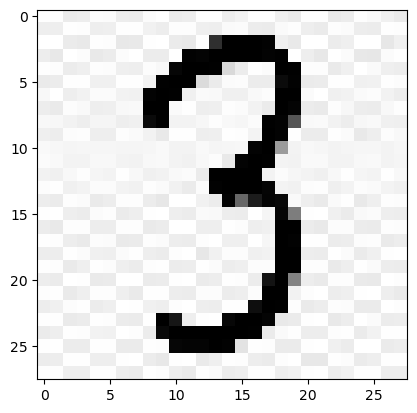

In [84]:
t = cv2.imread("./data/hand3.jpg", cv2.IMREAD_GRAYSCALE)
t = cv2.resize(t, (28,28))
plt.imshow(t, cmap="gray")

In [85]:
t.resize(1,28,28)

In [86]:
arr_t = torch.nn.functional.softmax(
    binary_cnn(torch.tensor(t).float()/255),
    dim=0
)
arr_t

tensor([[0.0012],
        [0.9988]], grad_fn=<SoftmaxBackward0>)

In [87]:
decipher_class(arr_t)

Predicted: Five


Again, a wrong prediction, it could be the model is overfitting the training dataset.

###  TODO
- [ ] Make the model not overfit and re-try custom inputs

Perhaps the network is too shallow and requires a linear layer at the end instead of 2-pixel output.

### 10-digit classification

Use the same architecture, but make the output predict 10 digits instead of two.

In [88]:
# Build model
classifier = torch.nn.Sequential(
    # Input channel 1 - grayscale imges
    torch.nn.Conv2d(1, 4, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 4 feature maps, each 14x14 pixels
    torch.nn.Conv2d(4, 8, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 8 feature maps, each 7x7 pixels
    torch.nn.Conv2d(8, 16, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # 16 feature maps, each 4x4 pixels
    torch.nn.Conv2d(16, 32, kernel_size=(3,3), stride=(2,2), padding=(1, 1)),
    torch.nn.ReLU(), # # 32 feature maps, each 2x2 pixels
    torch.nn.Conv2d(32, 10, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1)),
    torch.nn.Flatten() # 10 feature maps 1x1 pixels
)

In [89]:
X_train_tens.reshape(-1, 1, 28, 28).shape

torch.Size([50000, 1, 28, 28])

In [92]:
# Build dataloaders
X_train_tens, y_train_tens, X_valid_tens, y_valid_tens = map(torch.tensor, (mnist_ds.train_x, mnist_ds.train_y, mnist_ds.valid_x, mnist_ds.valid_y))

X_train_tens = X_train_tens.reshape(-1, 1, 28, 28)
X_valid_tens = X_valid_tens.reshape(-1, 1, 28, 28)

train_ds = TensorDataset(X_train_tens, y_train_tens)
test_ds = TensorDataset(X_valid_tens, y_valid_tens)

bs = 64
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=bs, shuffle=True)

In [93]:
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    classifier.parameters(),
    lr=1e-4
)
epoch = 1
train_ds_size = len(train_dl.dataset)
for e in range(epoch):
    print(f"Epoch: {e}")
    classifier.train()
    for batch, (X, y) in enumerate(train_dl):
        preds = classifier(X)
        
        loss = loss_fn(preds, y)
        
        loss.backward()
        
        optimizer.step()
        optimizer.zero_grad()
        
        if batch%100==0:
            print(f"Loss: {loss:.3f}  Batch: {batch * bs} \ {train_ds_size}")
            
    

Epoch: 0
Loss: 2.299  Batch: 0 \ 50000
Loss: 2.297  Batch: 6400 \ 50000
Loss: 2.276  Batch: 12800 \ 50000
Loss: 2.083  Batch: 19200 \ 50000
Loss: 1.635  Batch: 25600 \ 50000
Loss: 1.061  Batch: 32000 \ 50000
Loss: 0.698  Batch: 38400 \ 50000
Loss: 0.847  Batch: 44800 \ 50000


In [94]:
test_model(classifier, loss_fn, test_dl)

Accuracy 82.47%
 Avg. Loss: 0.626


In [95]:
torch.argmax(
    torch.nn.functional.softmax(
        classifier(torch.tensor(t).float()),
        dim=0,
    )
)

tensor(5)

---

## LeNet

Description: https://www.doc.ic.ac.uk/~bkainz/teaching/DL/notes/LeNet.pdf

https://www.geeksforgeeks.org/computer-vision/what-is-lenet/#description-of-lenets-architecture

### Architecture:

- inputs 1x28x28 images

**Convolution1**:
- input: 1x28x28, ks=(5,5), pad=2
- out: 6x(28x28)

**Activation1: Tanh()**

**Pooling1: Avg. pooling**
- input: 628x28, stride=2, ks=2
- out: 6x(14x14)

**Convolution2:**
- input: 6x(14x14), ks=(5,5)
- out: 16x(10x10)

**Activation2: Tanh()**

**Pooling2: Avg. pooling: ks=(2,2), stride=2**
- input size: 16*(10x10)
- output feature map size: 16:(5,5)
        
**Flatten**
- output size: $16*5*5=400$

**Linear1**
- input: 400
- ouput: 120

**Activation3: Tanh()**

**Linear2:**
- input: 120
- ouput: 84

**Activation4: Tanh()**

**Linear3:**
- input: 84
- output: 10

**Logits**
- final output
- feed to softmax

In [96]:
class LeNet5(torch.nn.Module):
    def __init__(self):
        super().__init__()
        
        # Input size 28x28
        self.conv1 = torch.nn.Conv2d(1, 6, (5,5), padding=2)
        # Out feature map size: 6*(28x28)
        
        self.act1 = torch.nn.Tanh()
        # self.act1 = torch.nn.ReLU()
        
        # Input size 6*(28x28)
        self.pool1 = torch.nn.AvgPool2d(kernel_size=(2,2), stride=2)
        # Out feature map size: 6*(14x14)
        
        # Input size 6*(14x14)
        self.conv2 = torch.nn.Conv2d(6, 16, (5,5))
        # Out feature maps size: 16*(10x10)
        
        # Activation
        self.act2 = torch.nn.Tanh()
        
        # Input size: 16*(10x10)
        self.pool2 = torch.nn.AvgPool2d(kernel_size=(2,2), stride=2)
        # Output feature map size: 16:(5,5)
        
        # Flatten the inputs for the linear layers
        self.flatten = torch.nn.Flatten()
        
        # Fully connected - Linear layers
        self.fc1 = torch.nn.Linear(16*5*5, 120)
        self.act3 = torch.nn.Tanh()
        
        self.fc2 = torch.nn.Linear(120, 84)
        self.act4 = torch.nn.Tanh()
        
        self.fc3 = torch.nn.Linear(84, 10)
        
    def forward(self, x):
        
        # 1
        x = self.conv1(x)
        x = self.act1(x)
        x = self.pool1(x)
        
        # 2
        x = self.conv2(x)
        x = self.act2(x)
        x = self.pool2(x)
        
        x = self.flatten(x)
        
        # 3
        x = self.fc1(x)
        x = self.act3(x)
        
        # 4
        x = self.fc2(x)
        x = self.act4(x)
        
        # 5
        x = self.fc3(x)
        
        return x
        

In [97]:
lenet = LeNet5()
lenet

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (act1): Tanh()
  (pool1): AvgPool2d(kernel_size=(2, 2), stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (act2): Tanh()
  (pool2): AvgPool2d(kernel_size=(2, 2), stride=2, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (act3): Tanh()
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (act4): Tanh()
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [98]:
lenet = LeNet5()
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    lenet.parameters(),
    lr=1e-3
)

train_function(lenet, loss_fn, optimizer, train_dl)

loss: 2.304  Batch: [0 / 50000]
loss: 2.096  Batch: [640 / 50000]
loss: 1.655  Batch: [1280 / 50000]
loss: 1.015  Batch: [1920 / 50000]
loss: 0.965  Batch: [2560 / 50000]
loss: 0.668  Batch: [3200 / 50000]
loss: 0.730  Batch: [3840 / 50000]
loss: 0.547  Batch: [4480 / 50000]
loss: 0.425  Batch: [5120 / 50000]
loss: 0.395  Batch: [5760 / 50000]
loss: 0.427  Batch: [6400 / 50000]
loss: 0.369  Batch: [7040 / 50000]
loss: 0.452  Batch: [7680 / 50000]
loss: 0.384  Batch: [8320 / 50000]
loss: 0.386  Batch: [8960 / 50000]
loss: 0.300  Batch: [9600 / 50000]
loss: 0.427  Batch: [10240 / 50000]
loss: 0.225  Batch: [10880 / 50000]
loss: 0.251  Batch: [11520 / 50000]
loss: 0.181  Batch: [12160 / 50000]
loss: 0.441  Batch: [12800 / 50000]
loss: 0.428  Batch: [13440 / 50000]
loss: 0.302  Batch: [14080 / 50000]
loss: 0.205  Batch: [14720 / 50000]
loss: 0.129  Batch: [15360 / 50000]
loss: 0.246  Batch: [16000 / 50000]
loss: 0.323  Batch: [16640 / 50000]
loss: 0.212  Batch: [17280 / 50000]
loss: 0.223 

In [99]:
test_model(lenet, loss_fn, test_dl)

Accuracy 96.00%
 Avg. Loss: 0.137


In [101]:
# Test with a custom number - online
torch.argmax(
    torch.nn.functional.softmax(
        lenet(
            torch.tensor(
                mnist_ds.train_x[0].reshape(1, 1, 28,28)
            )
        ),
        dim=1
    )
)

tensor(5)

---

## AlexNet


- 

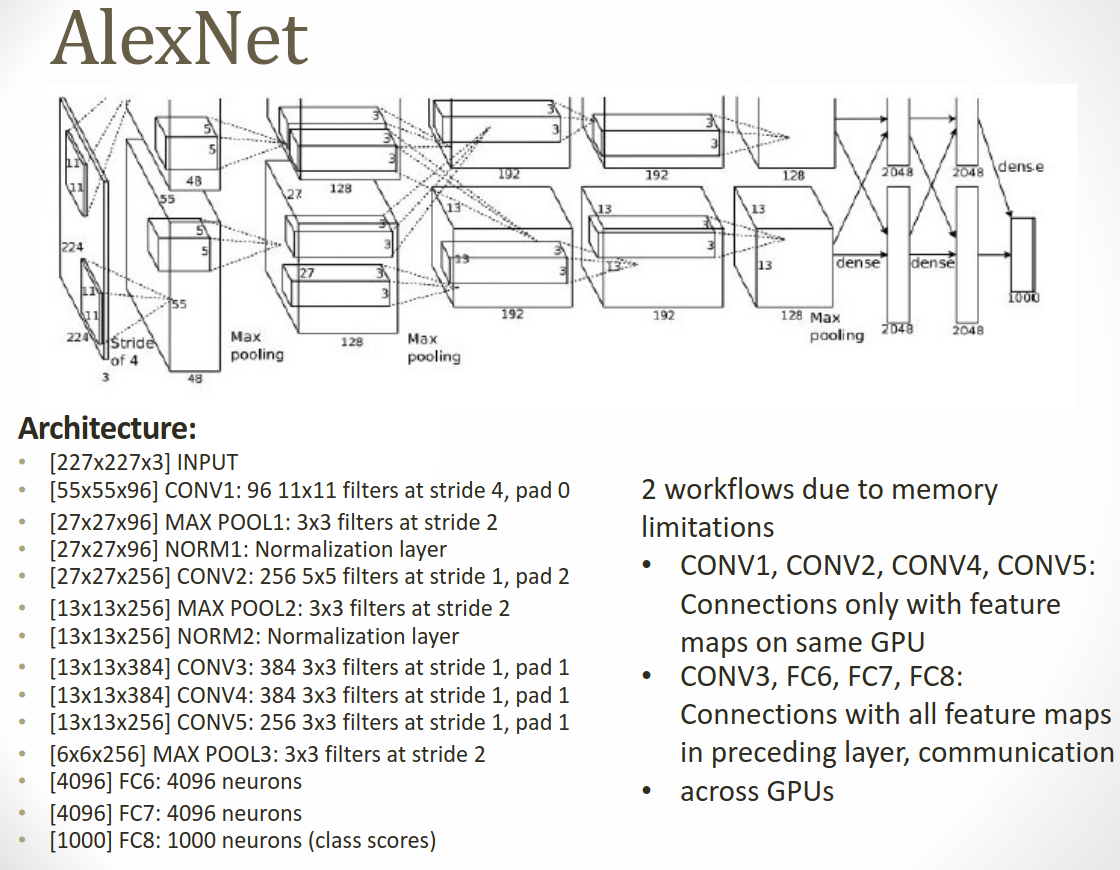
Image from the lecture: multimedia in AI

Differences with LeNet:
- 5 convolutional layers instead of 2
- 2 Normalization layers - Local Response Normalization
- 3 MaxPool layers: 1st, 2nd, 5th convolution
- ReLU activation function instead of Tanh
- MaxPooling instead of AvgPooling

### Architecture

**Conv1**
- input:
- output:

**Act1**
- ReLU

**Normalization1**
- LocalResponseNorm

**Pooling1**
- MaxPool


**Conv2**
- input:
- output:

**Act2**
- ReLU

**Normalization2**
- LocalResponseNorm

**Pooling2**
- MaxPool

**Conv3**
- input:
- output:

**Act3**
- ReLU

**Conv4**
- input:
- output:

**Act4**
- ReLU


**Conv5**
- input:
- output:

**Act5**
- ReLU

**Pooling3**
- MaxPool

**Flatten**
- input for linear layers

**Linear1**

**Act6**
- ReLU

**Linear2**

**Act7**
- ReLU

**Linear3**
- output(logits) == nof classes

## TODO

- [ ] implement AlexNet for CIFAR-10 RGB images
- [ ] implement CIFAR-10 dataset in `mikroml`: https://www.cs.toronto.edu/~kriz/cifar.html

## MobileNets

## ViT / Swin

## SOAT
- vision Mamba (SSM)
- Dino